Realizado por:
Andrea Bonilla
July Aparicio
Ioshua Castillejos

# Clasificación de Sentimientos de Reseñas de Películas en IMDb con Redes Neuronales Recurrentes
## A - Objetivo

Desarrollar un método basado en redes neuronales recurrentes que permita clasificar con precisión las reseñas de películas en IMDb en una de las dos
categorías: positiva o negativa

## B - Conjunto de datos

Los datos corresponden a un dataset de reseñas de películas en IMDb,
disponibles en el siguiente enlace. El dataset contiene miles de reseñas
etiquetadas con su correspondiente rating y etiqueta de sentimiento (positivo o
negativo)

## C - Actividades por realizar
1. Preprocesamiento de las reseñas: Construir un pipeline que permita limpiar y
tokenizar las reseñas de texto, convirtiéndolas en secuencias numéricas
utilizando embeddings
2. Desarrollo de la arquitectura de red neuronal recurrente: Implementar una
RNN (por ejemplo, LSTM o GRU) para la clasificación de las reseñas en dos
categorías. La arquitectura de la red es de libre elección, pero se sugiere incluir
capas de embedding, capas recurrentes y una capa densa de salida con
activación sigmoide. Justificar la elección de cada capa del modelo.
3. Entrenamiento y evaluación del modelo: Dividir el dataset en conjuntos de
entrenamiento, validación y prueba. Entrenar el modelo utilizando el conjunto de
entrenamiento y evaluar su rendimiento con el conjunto de prueba, reportando
métricas de precisión, recall y F1-score.

### 1. Librerías

In [1]:
# Librerías requeridas
# PyTorch para construir y entrenar las redes
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split


import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader, random_split

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler

from time import time
from gensim.models import Word2Vec
from nltk.stem import PorterStemmer
stemmer = PorterStemmer()

import copy

# Para descargar los recursos desde la red con proxy (error de certificado SSL)
try:
    import truststore
    truststore.inject_into_ssl()
except ImportError:
    pass

import nltk
from nltk.corpus import stopwords
from wordcloud import WordCloud

# Se descargan los recursos de NLTK si no están instalados
for recurso, ruta in [('punkt', 'tokenizers/punkt'),
                      ('punkt_tab', 'tokenizers/punkt_tab'),
                      ('stopwords', 'corpora/stopwords')]:
    try:
        nltk.data.find(ruta)
    except LookupError:
        nltk.download(recurso, quiet=True)

# Semillas
torch.manual_seed(5)
np.random.seed(5)

# Se usa GPU si está disponible
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Usando dispositivo: {device}')

# Librerías para el modelo con GloVe
import os
from collections import Counter
from gensim.models import KeyedVectors
import gensim.downloader as api

Usando dispositivo: cuda


### 2. Importar los datos

In [2]:
GHI = pd.read_csv('movie.csv')
GHI.info()

<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    40000 non-null  str  
 1   label   40000 non-null  int64
dtypes: int64(1), str(1)
memory usage: 50.6 MB


### 3. Exploración de datos

In [3]:
GHI.head()

,text,label
0,I grew up (b. 1965) watching and loving the Th...,0
1,"When I put this movie in my DVD player, and sa...",0
2,Why do people who do not know what a particula...,0
3,Even though I have great interest in Biblical ...,0
4,Im a die hard Dads Army fan and nothing will e...,1


In [4]:
GHI['label'].value_counts()

label
0    20019
1    19981
Name: count, dtype: int64

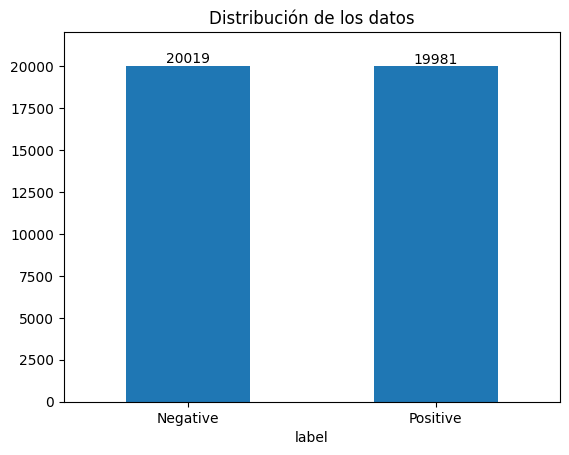

In [5]:
ax = GHI.groupby('label').count().plot(kind='bar', title='Distribución de los datos',
                                       legend=False)
ax.set_xticklabels(['Negative', 'Positive'], rotation=0)

for container in ax.containers:
    ax.bar_label(container)

ax.margins(y=0.1)  # espacio para las etiquetas


In [6]:
longitudes = GHI['text'].str.split().str.len()
print(f"Textos muy cortos (<5 palabras): {(longitudes < 5).sum()}")
print(f"Textos muy largos (>1000 palabras): {(longitudes > 1000).sum()}")
print(f"Filas con registros nulos: {GHI['text'].isnull().sum()}")
print(f"Filas invalidas: {GHI['text'].isna().sum()}")
print(f"Filas duplicadas: {GHI['text'].duplicated().sum()}")

Textos muy cortos (<5 palabras): 1
Textos muy largos (>1000 palabras): 60
Filas con registros nulos: 0
Filas invalidas: 0
Filas duplicadas: 277


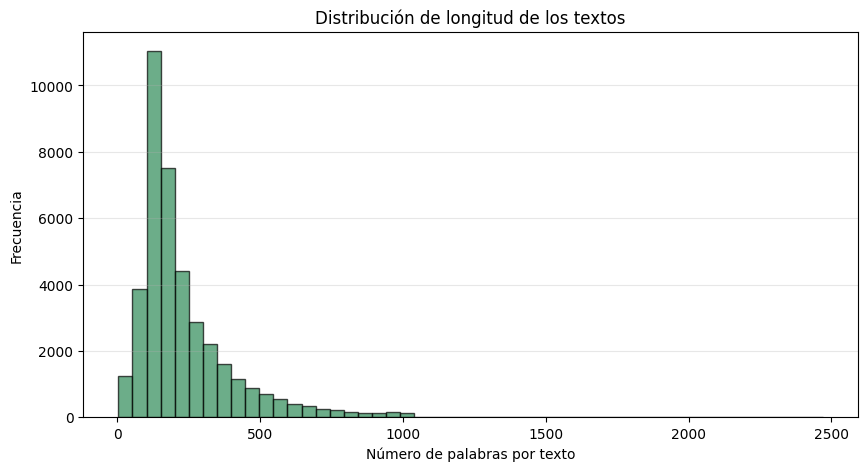

count    40000.000000
mean       231.339250
std        171.194123
min          4.000000
25%        126.000000
50%        173.000000
75%        282.000000
max       2470.000000
Name: text, dtype: float64


In [7]:
longitudes = GHI['text'].str.split().str.len()

plt.figure(figsize=(10,5))
plt.hist(longitudes, bins=50, color='seagreen', edgecolor='black', alpha=0.7)
plt.xlabel('Número de palabras por texto')
plt.ylabel('Frecuencia')
plt.title('Distribución de longitud de los textos')
plt.grid(axis='y', alpha=0.3)
plt.show()

print(longitudes.describe())

Hallazgos de la exploración de datos.

Las dos clases están casi balanceadas (20.019 reseñas negativas y 19.981 positivas), por lo que no fue necesario balancear los datos. No hay valores nulos, pero sí 277 reseñas repetidas, que se eliminan antes de dividir los datos. En promedio las reseñas tienen 231 palabras y la mediana es de 173; la más corta tiene 4 palabras y la más larga 2.470, por eso el histograma tiene una cola larga hacia la derecha. Solo una reseña tiene menos de 5 palabras y 60 tienen más de 1.000.

### 4. Separación de datos

Primero se eliminan las reseñas duplicadas, para que una misma reseña no quede a la vez en entrenamiento y en prueba; quedan 39.723 registros. Después los datos se dividen en 70 % entrenamiento (27.806), 15 % validación (5.958) y 15 % prueba (5.959), estratificando por la etiqueta para mantener la proporción de clases. La división usa la semilla 5.

In [8]:
# Se quitan los duplicados antes de dividir
GHI = GHI.drop_duplicates(subset='text').reset_index(drop=True)
print(f"Registros tras eliminar duplicados: {len(GHI)}")

SEED = 5

# 70% train, 15% validación, 15% prueba
train_GHI, resto = train_test_split(GHI, test_size=0.30, stratify=GHI["label"], random_state=SEED)
val_GHI, test_GHI = train_test_split(resto, test_size=0.50, stratify=resto["label"], random_state=SEED)
print(f"Datos entrenamiento: {len(train_GHI)}\nDatos validacion: {len(val_GHI)} \nDatos prueba: {len(test_GHI)}")

Registros tras eliminar duplicados: 39723
Datos entrenamiento: 27806
Datos validacion: 5958 
Datos prueba: 5959


### 5. Función de limpieza de textos

La función `limpiar_texto` convierte las entidades HTML (`&amp;`), quita las etiquetas HTML como `<br />` y las URLs, y pasa todo a minúsculas. Las negaciones contraídas se separan (*won't* → *will not*, *can't* → *can not*, *didn't* → *did not*), las demás contracciones (*'s*, *'re*, *'ll*...) se eliminan y se dejan solo letras.

Después se quitan las stopwords de NLTK y las palabras de una sola letra, pero se conservan *no*, *nor*, *not*, *but*, *very*, *too*, *against* y *only*, porque cambian el sentido de la reseña. Por último cada palabra se reduce a su raíz con el stemmer de Porter (*movies* → *movi*). La limpieza se aplica a los tres conjuntos y el resultado queda en la columna `palabras_limpias`.

In [9]:
import re
import html

# Se conservan las negaciones y palabras que cambian el sentido
conservar = {'no', 'nor', 'not', 'but', 'very', 'too', 'against', 'only'}
stop_words = set(stopwords.words('english')) - conservar

def limpiar_texto(texto, quitar_stopwords=True):
    texto = html.unescape(texto)
    texto = re.sub(r'<[^>]+>', ' ', texto)  # html
    texto = re.sub(r'http\S+|www\.\S+', ' ', texto)  # urls
    texto = texto.lower().replace('\u2019', "'")  # minúsculas
    texto = re.sub(r"\bwon't\b", 'will not', texto)  # negaciones
    texto = re.sub(r"\bcan't\b", 'can not', texto)
    texto = re.sub(r"n't\b", ' not', texto)
    texto = re.sub(r"'(s|re|ve|d|ll|m)\b", ' ', texto)  # contracciones
    texto = re.sub(r'[^a-z\s]', ' ', texto)  # solo letras
    palabras_limpias = texto.split()
    if quitar_stopwords:
        palabras_limpias = [t for t in palabras_limpias if t not in stop_words and len(t) > 1]
        palabras_limpias = [stemmer.stem(t) for t in palabras_limpias]
    # Retorna la lista de palabras limpias
    return palabras_limpias

print(limpiar_texto("I didn't like it.<br /><br />It WASN'T good &amp; I can't recommend it!!"))

# Limpieza de train, validación y prueba
for conjunto in (train_GHI, val_GHI, test_GHI):
    conjunto['palabras_limpias'] = conjunto['text'].apply(limpiar_texto)

['not', 'like', 'not', 'good', 'not', 'recommend']


### 6. Vocabulario y secuencias

El vocabulario se construye solo con los datos de entrenamiento, para no filtrar información de validación y prueba. El 0 es para el padding, el 1 para las palabras desconocidas y el resto para las 19.998 palabras más frecuentes (20.000 índices en total). Cada reseña se convierte en una secuencia de 300 índices: si es corta se rellena con ceros al inicio y si es larga se conserva el inicio. Los lotes son de 128 para entrenamiento y de 256 para validación y prueba.

In [10]:
MAX_VOCAB = 20000
MAX_LEN = 300
EMB_DIM = 300

# 0 = padding, 1 = desconocida
contador = Counter(t for toks in train_GHI["palabras_limpias"] for t in toks)
palabras = [p for p, _ in contador.most_common(MAX_VOCAB - 2)]
word2idx = {p: i + 2 for i, p in enumerate(palabras)}

def codificar(tokens):
    ids = [word2idx.get(t, 1) for t in tokens][:MAX_LEN]   # se deja el inicio de la reseña
    return [0] * (MAX_LEN - len(ids)) + ids

def a_tensores(df):
    X = torch.tensor([codificar(t) for t in df["palabras_limpias"]], dtype=torch.long)
    y = torch.tensor(df["label"].values, dtype=torch.float32)
    return X, y

X_train, y_train = a_tensores(train_GHI)
X_val, y_val = a_tensores(val_GHI)
X_test, y_test = a_tensores(test_GHI)

train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=128, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=256)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=256)
print(X_train.shape, X_val.shape, X_test.shape)

torch.Size([27806, 300]) torch.Size([5958, 300]) torch.Size([5959, 300])


### 7. Embeddings GloVe

Se usan los vectores preentrenados de GloVe de 300 dimensiones. Si `glove.6B.300d.txt` está en la carpeta se lee de ahí; si no, se descarga con gensim (`glove-wiki-gigaword-300`). Con esos vectores se arma la matriz de embeddings en el orden del vocabulario. Las palabras que no están en GloVe quedan con un vector aleatorio (con la misma desviación estándar de los vectores de GloVe) y el padding en ceros. Hay que tener en cuenta que, como las palabras pasaron por stemming, muchas no se encuentran en GloVe.

In [11]:
if os.path.exists("glove.6B.300d.txt"):
    glove = KeyedVectors.load_word2vec_format("glove.6B.300d.txt", binary=False, no_header=True)
else:
    glove = api.load("glove-wiki-gigaword-300")

print(glove.most_similar("great", topn=5))
print(glove.most_similar("terrible", topn=5))

encontradas = [p for p in word2idx if p in glove]
desv = np.std([glove[p] for p in encontradas])
rng = np.random.default_rng(SEED)

emb_matrix = rng.normal(scale=desv, size=(MAX_VOCAB, EMB_DIM)).astype(np.float32)
emb_matrix[0] = 0
for palabra in encontradas:
    emb_matrix[word2idx[palabra]] = glove[palabra]
print(f"Palabras con vector de GloVe: {len(encontradas):,} de {len(word2idx):,}")

del glove

[('greatest', 0.6583032608032227), ('good', 0.6410046815872192), ('tremendous', 0.6299972534179688), ('well', 0.5856286883354187), ('especially', 0.5592252612113953)]
[('horrible', 0.8621524572372437), ('awful', 0.7882837653160095), ('dreadful', 0.7239290475845337), ('horrendous', 0.6983873844146729), ('horrific', 0.6624177098274231)]
Palabras con vector de GloVe: 14,138 de 19,998


### 8. Modelo

La primera capa es el embedding de 300 dimensiones, inicializado con la matriz de GloVe. Así el modelo no empieza desde cero y ya trae relaciones entre palabras. Se deja entrenable para que se ajuste a las reseñas. Después se agrega un dropout de 0.3 para reducir el sobreajuste.

Luego van dos capas LSTM de 128 unidades, con un dropout de 0.3 entre ellas. Se escogió LSTM y no una RNN simple porque las reseñas son largas (se cortan en 300 tokens) y la RNN simple pierde la información del principio por el desvanecimiento del gradiente.

Después de la LSTM va una capa de atención. Una capa lineal le da un puntaje a cada palabra, se aplica softmax y con esos pesos se hace un promedio de las salidas de la LSTM. De esta forma el modelo no depende solo del último estado y puede darle más importancia a palabras como *awful* o *masterpiece*. El padding se enmascara para que no cuente.

Al final van otro dropout de 0.3 y una neurona con sigmoide que da la probabilidad de que la reseña sea positiva. Si es 0.5 o más, se clasifica como positiva. La función de pérdida es `BCELoss`.

El entrenamiento se hace con Adam (lr = 0.001, weight decay = 1e-5) y la norma del gradiente se recorta a 1.0 para que los gradientes de la LSTM no se disparen. El modelo con Word2Vec usa esta misma arquitectura, para poder comparar los dos embeddings.

In [12]:
class SentimentLSTM(nn.Module):
    def __init__(self, vocab_size, emb_dim=100, hidden_dim=128, num_layers=2, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.emb_dropout = nn.Dropout(dropout)
        self.lstm = nn.LSTM(emb_dim, hidden_dim, num_layers=num_layers,
                            batch_first=True, dropout=dropout if num_layers > 1 else 0)
        self.atencion = nn.Linear(hidden_dim, 1)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        mascara = (x != 0)
        emb = self.emb_dropout(self.embedding(x))
        salida, _ = self.lstm(emb)

        # atención (sin contar el padding)
        puntajes = self.atencion(salida).squeeze(-1)
        puntajes = puntajes.masked_fill(~mascara, -1e9)
        pesos = torch.softmax(puntajes, dim=1)
        h = (salida * pesos.unsqueeze(-1)).sum(dim=1)

        h = self.dropout(h)
        return self.sigmoid(self.fc(h)).squeeze(1)

torch.manual_seed(SEED)
modelo = SentimentLSTM(emb_matrix.shape[0], EMB_DIM).to(device)
modelo.embedding.weight.data.copy_(torch.tensor(emb_matrix))
modelo.embedding.weight.requires_grad = True
criterio = nn.BCELoss()
optimizador = optim.Adam(modelo.parameters(), lr=1e-3, weight_decay=1e-5)  # regularización L2
# Se reduce el lr a la mitad si la pérdida de validación no baja
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizador, mode="min", factor=0.5, patience=1)

print(modelo)
print(f"Parámetros entrenables: {sum(p.numel() for p in modelo.parameters() if p.requires_grad):,}")

SentimentLSTM(
  (embedding): Embedding(20000, 300, padding_idx=0)
  (emb_dropout): Dropout(p=0.3, inplace=False)
  (lstm): LSTM(300, 128, num_layers=2, batch_first=True, dropout=0.3)
  (atencion): Linear(in_features=128, out_features=1, bias=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)
Parámetros entrenables: 6,352,514


### 9. Entrenamiento con validación

En cada época el modelo se entrena con train y se evalúa con validación. Se guarda el modelo con menor pérdida de validación y se usa early stopping con paciencia de 10 épocas (máximo 50). Si la pérdida de validación no baja, `ReduceLROnPlateau` reduce la tasa de aprendizaje a la mitad. Al terminar se cargan los pesos del mejor modelo y se grafican las curvas de pérdida y accuracy.

In [13]:
def ejecutar_epoca(loader, entrenar):
    modelo.train() if entrenar else modelo.eval()
    perdida_total, aciertos, n = 0.0, 0, 0
    with torch.set_grad_enabled(entrenar):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            prob = modelo(xb)
            perdida = criterio(prob, yb)
            if entrenar:
                optimizador.zero_grad()
                perdida.backward()
                nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
                optimizador.step()
            perdida_total += perdida.item() * len(yb)
            aciertos += ((prob >= 0.5).float() == yb).sum().item()
            n += len(yb)
    return perdida_total / n, aciertos / n

EPOCAS = 50
PACIENCIA = 10

historial = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
mejor_val_loss = float("inf")
mejor_estado = None
sin_mejora = 0
inicio = time()

for epoca in range(1, EPOCAS + 1):
    tr_loss, tr_acc = ejecutar_epoca(train_loader, entrenar=True)
    va_loss, va_acc = ejecutar_epoca(val_loader, entrenar=False)
    scheduler.step(va_loss)
    for k, v in zip(historial, (tr_loss, va_loss, tr_acc, va_acc)):
        historial[k].append(v)
    print(f"Época {epoca:2d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
          f"val loss {va_loss:.4f} acc {va_acc:.4f} | lr {optimizador.param_groups[0]['lr']:.1e}")

    if va_loss < mejor_val_loss:
        mejor_val_loss = va_loss
        mejor_estado = copy.deepcopy(modelo.state_dict())
        sin_mejora = 0
    else:
        sin_mejora += 1
        if sin_mejora >= PACIENCIA:
            print(f"Early stopping: la pérdida de validación no mejora hace {PACIENCIA} épocas")
            break

modelo.load_state_dict(mejor_estado)  # mejor modelo
print(f"Tiempo de entrenamiento: {time() - inicio:.1f} s | mejor val loss: {mejor_val_loss:.4f}")

Época  1 | train loss 0.4230 acc 0.8009 | val loss 0.3057 acc 0.8708 | lr 1.0e-03
Época  2 | train loss 0.2586 acc 0.8969 | val loss 0.2839 acc 0.8842 | lr 1.0e-03
Época  3 | train loss 0.2021 acc 0.9225 | val loss 0.2841 acc 0.8884 | lr 1.0e-03
Época  4 | train loss 0.1570 acc 0.9418 | val loss 0.3026 acc 0.8860 | lr 5.0e-04
Época  5 | train loss 0.1061 acc 0.9644 | val loss 0.3921 acc 0.8778 | lr 5.0e-04
Época  6 | train loss 0.0892 acc 0.9689 | val loss 0.3850 acc 0.8788 | lr 2.5e-04
Época  7 | train loss 0.0644 acc 0.9793 | val loss 0.4602 acc 0.8800 | lr 2.5e-04
Época  8 | train loss 0.0552 acc 0.9827 | val loss 0.4753 acc 0.8775 | lr 1.3e-04
Época  9 | train loss 0.0461 acc 0.9855 | val loss 0.4992 acc 0.8743 | lr 1.3e-04
Época 10 | train loss 0.0444 acc 0.9868 | val loss 0.5260 acc 0.8751 | lr 6.3e-05
Época 11 | train loss 0.0397 acc 0.9881 | val loss 0.5330 acc 0.8750 | lr 6.3e-05
Época 12 | train loss 0.0365 acc 0.9891 | val loss 0.5455 acc 0.8751 | lr 3.1e-05
Early stopping: 

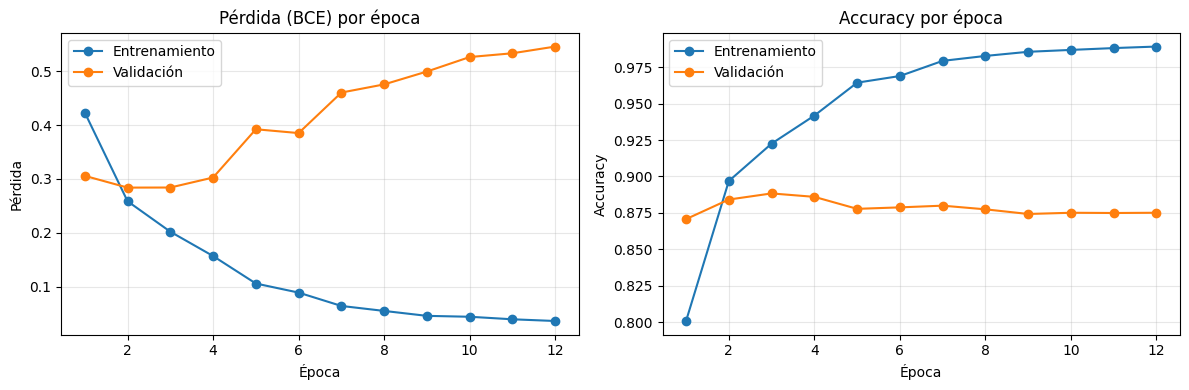

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epocas_x = range(1, len(historial["train_loss"]) + 1)

axes[0].plot(epocas_x, historial["train_loss"], marker="o", label="Entrenamiento")
axes[0].plot(epocas_x, historial["val_loss"], marker="o", label="Validación")
axes[0].set_title("Pérdida (BCE) por época")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Pérdida")

axes[1].plot(epocas_x, historial["train_acc"], marker="o", label="Entrenamiento")
axes[1].plot(epocas_x, historial["val_acc"], marker="o", label="Validación")
axes[1].set_title("Accuracy por época")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Accuracy")

for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

### 10. Evaluación en el conjunto de prueba

El mejor modelo se evalúa una sola vez con el conjunto de prueba (15 %), que no se usó ni para entrenar ni para escoger el modelo. Se reportan accuracy, precisión, recall, F1-score y la matriz de confusión.

Accuracy : 0.8861
Precisión: 0.9133
Recall   : 0.8537
F1-score : 0.8825

              precision    recall  f1-score   support

    Negativa     0.8621    0.9186    0.8894      2973
    Positiva     0.9133    0.8537    0.8825      2986

    accuracy                         0.8861      5959
   macro avg     0.8877    0.8861    0.8859      5959
weighted avg     0.8877    0.8861    0.8859      5959



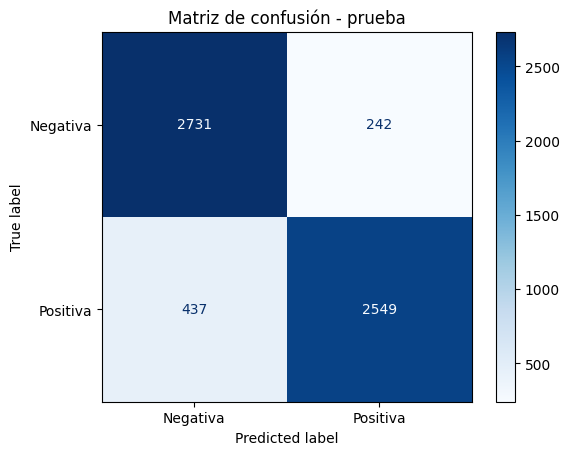

In [15]:
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score)

modelo.eval()
probs, reales = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        probs.append(modelo(xb.to(device)).cpu())
        reales.append(yb)
probs = torch.cat(probs).numpy()
y_real = torch.cat(reales).numpy().astype(int)
y_pred = (probs >= 0.5).astype(int)

print(f"Accuracy : {accuracy_score(y_real, y_pred):.4f}")
print(f"Precisión: {precision_score(y_real, y_pred):.4f}")
print(f"Recall   : {recall_score(y_real, y_pred):.4f}")
print(f"F1-score : {f1_score(y_real, y_pred):.4f}")
print()
print(classification_report(y_real, y_pred, target_names=["Negativa", "Positiva"], digits=4))

ConfusionMatrixDisplay(confusion_matrix(y_real, y_pred),
                       display_labels=["Negativa", "Positiva"]).plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión - prueba")
plt.show()

### 11. Pérdida en test, AUC y accuracy por longitud

Se calcula la pérdida en prueba para compararla con la de validación, y el AUC de la curva ROC. También se revisa el accuracy según la cantidad de tokens de cada reseña, para ver si el modelo falla más en las reseñas cortas o en las de más de 300 tokens, que quedan recortadas.

Pérdida test: 0.2813 | mejor pérdida validación: 0.2839
AUC test: 0.9554
         reseñas  accuracy
rango                     
0-50         623    0.8941
51-100      2589    0.8903
101-200     1809    0.8778
201-300      561    0.8895
>300         377    0.8780


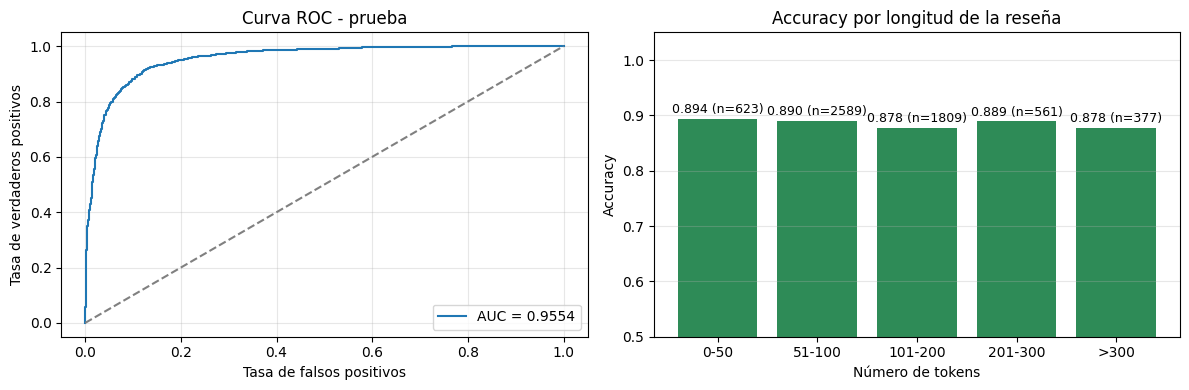

In [16]:
from sklearn.metrics import roc_auc_score, roc_curve

# pérdida en test (el modelo ya devuelve probabilidades)
test_loss = criterio(torch.tensor(probs), torch.tensor(y_real, dtype=torch.float32)).item()
auc = roc_auc_score(y_real, probs)
print(f"Pérdida test: {test_loss:.4f} | mejor pérdida validación: {min(historial['val_loss']):.4f}")
print(f"AUC test: {auc:.4f}")

# test_loader no tiene shuffle, el orden es el mismo de test_GHI
resultados = pd.DataFrame({
    "n_tokens": test_GHI["palabras_limpias"].str.len().values,
    "real": y_real,
    "pred": y_pred,
    "prob": probs,
})
resultados["acierto"] = (resultados["real"] == resultados["pred"]).astype(int)

cortes = [0, 50, 100, 200, 300, np.inf]
etiquetas = ["0-50", "51-100", "101-200", "201-300", ">300"]
resultados["rango"] = pd.cut(resultados["n_tokens"], bins=cortes, labels=etiquetas)
por_longitud = resultados.groupby("rango", observed=False).agg(reseñas=("acierto", "size"),
                                                               accuracy=("acierto", "mean"))
print(por_longitud.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

fpr, tpr, _ = roc_curve(y_real, probs)
axes[0].plot(fpr, tpr, label=f"AUC = {auc:.4f}")
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set_title("Curva ROC - prueba")
axes[0].set_xlabel("Tasa de falsos positivos")
axes[0].set_ylabel("Tasa de verdaderos positivos")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].bar(etiquetas, por_longitud["accuracy"], color="seagreen")
for i, (acc, n) in enumerate(zip(por_longitud["accuracy"], por_longitud["reseñas"])):
    axes[1].text(i, acc + 0.01, f"{acc:.3f} (n={n})", ha="center", fontsize=9)
axes[1].set_ylim(0.5, 1.05)
axes[1].set_title("Accuracy por longitud de la reseña")
axes[1].set_xlabel("Número de tokens")
axes[1].set_ylabel("Accuracy")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### 12. Ejemplos de errores

Para entender en qué se equivoca el modelo, se revisan los errores en los que estaba más seguro: las reseñas negativas con mayor probabilidad de ser positivas (falsos positivos) y las positivas con menor probabilidad (falsos negativos). Se muestran 5 de cada tipo.

In [17]:
resultados["texto"] = test_GHI["text"].str.replace("<br />", " ").values

fp = resultados[(resultados["real"] == 0) & (resultados["pred"] == 1)]
fn = resultados[(resultados["real"] == 1) & (resultados["pred"] == 0)]
print("Falsos positivos:", len(fp))
print("Falsos negativos:", len(fn))

print("----- Falsos positivos (negativas que el modelo dio como positivas) -----")
for _, fila in fp.sort_values("prob", ascending=False).head(5).iterrows():
    print(f"Probabilidad: {fila['prob']:.3f} | Tokens: {fila['n_tokens']}")
    print(fila["texto"][:500])

print("----- Falsos negativos (positivas que el modelo dio como negativas) -----")
for _, fila in fn.sort_values("prob").head(5).iterrows():
    print(f"Probabilidad: {fila['prob']:.3f} | Tokens: {fila['n_tokens']}")
    print(fila["texto"][:500])

Falsos positivos: 242
Falsos negativos: 437
----- Falsos positivos (negativas que el modelo dio como positivas) -----
Probabilidad: 0.998 | Tokens: 26
this is a great movie. I love the series on tv and so I loved the movie. One of the best things in the movie is that Helga finally admits her deepest darkest secret to Arnold!!! that was great. i loved it it was pretty funny too. It's a great movie! Doy!!!
Probabilidad: 0.995 | Tokens: 23
This is, without a doubt, the most hilarious movie I've ever seen. Seriously, if the makers of this movie are ever discovered, they'll put guys like Jim Carrey out of a job. Rent "Jack-O" tonight! Believe me, you won't regret it!
Probabilidad: 0.995 | Tokens: 39
This movie was pure genius. John Waters is brilliant. It is hilarious and I am not sick of it even after seeing it about 20 times since I bought it a few months ago. The acting is great, although Ricki Lake could have been better. And Johnny Depp is magnificent. He is such a beautiful man and a 

## Modelo con embeddings Word2Vec (comparación con GloVe 300d)

Para comparar, también se entrena un modelo con embeddings Word2Vec de 100 dimensiones entrenados con las reseñas del conjunto de entrenamiento. Se usan los mismos conjuntos de entrenamiento, validación y prueba y el mismo vocabulario. Las variables de esta parte llevan el sufijo `_w2v` para no perder los resultados del modelo con GloVe.

### 13. Embeddings Word2Vec

Word2Vec se entrena solo con las reseñas de entrenamiento, con vectores de 100 dimensiones, ventana de 5 y `min_count=1`.

In [18]:
from gensim.models import Word2Vec

EMB_DIM_W2V = 100

w2v = Word2Vec(
    sentences=train_GHI["palabras_limpias"].tolist(),
    vector_size=EMB_DIM_W2V,
    window=5,
    min_count=1,
    workers=4,
    seed=SEED,
)

print(f"Palabras en el modelo Word2Vec: {len(w2v.wv):,}")
print("Similares a 'great':", w2v.wv.most_similar('great', topn=5))

Palabras en el modelo Word2Vec: 53,672
Similares a 'great': [('excel', 0.7527596354484558), ('fine', 0.7451826930046082), ('fantast', 0.7305018901824951), ('good', 0.6866070628166199), ('awesom', 0.6745137572288513)]


### 14. Matriz con embeddings y tensores

Se usa el mismo vocabulario de 20.000 índices. Las secuencias se arman igual que para GloVe, con 300 índices, padding al inicio y conservando el inicio de las reseñas largas. Cada fila de la matriz toma el vector de Word2Vec de su palabra y el padding queda en ceros; como Word2Vec se entrenó con `min_count=1`, todas las palabras del vocabulario tienen vector. Los lotes son de 128 para entrenamiento y de 256 para validación y prueba.

In [19]:
MAX_LEN_W2V = 300
VOCAB_SIZE_W2V = len(word2idx) + 2

def codificar_w2v(tokens):
    ids = [word2idx.get(t, 1) for t in tokens][:MAX_LEN_W2V]
    # padding al inicio
    return [0] * (MAX_LEN_W2V - len(ids)) + ids

# Matriz de embeddings con los vectores de Word2Vec
matriz_emb_w2v = np.random.normal(0, 0.1, (VOCAB_SIZE_W2V, EMB_DIM_W2V)).astype("float32")
matriz_emb_w2v[0] = 0.0  # padding
encontradas_w2v = 0
for palabra, idx in word2idx.items():
    if palabra in w2v.wv:
        matriz_emb_w2v[idx] = w2v.wv[palabra]
        encontradas_w2v += 1
print(f"Palabras con vector Word2Vec: {encontradas_w2v:,} / {len(word2idx):,}")

def a_tensores_w2v(frame):
    X = torch.tensor([codificar_w2v(t) for t in frame["palabras_limpias"]], dtype=torch.long)
    y = torch.tensor(frame["label"].values, dtype=torch.float32)
    return X, y

X_train_w2v, y_train_w2v = a_tensores_w2v(train_GHI)
X_val_w2v, y_val_w2v = a_tensores_w2v(val_GHI)
X_test_w2v, y_test_w2v = a_tensores_w2v(test_GHI)

train_loader_w2v = DataLoader(TensorDataset(X_train_w2v, y_train_w2v), batch_size=128, shuffle=True)
val_loader_w2v = DataLoader(TensorDataset(X_val_w2v, y_val_w2v), batch_size=256)
test_loader_w2v = DataLoader(TensorDataset(X_test_w2v, y_test_w2v), batch_size=256)
print(X_train_w2v.shape, X_val_w2v.shape, X_test_w2v.shape)

Palabras con vector Word2Vec: 19,998 / 19,998
torch.Size([27806, 300]) torch.Size([5958, 300]) torch.Size([5959, 300])


### 15. Modelo Word2Vec

Se usa la misma clase `SentimentLSTM` del modelo con GloVe. Lo único que cambia es el embedding, que aquí es de 100 dimensiones y se inicializa con los vectores de Word2Vec. Lo demás es igual: dropout de 0.3, dos capas LSTM de 128 unidades, la capa de atención y la neurona de salida con sigmoide. Se entrena con `BCELoss`, Adam (lr = 0.001, weight decay = 1e-5) y `ReduceLROnPlateau`, y la norma del gradiente se recorta a 1.0.

In [20]:
# misma clase SentimentLSTM del modelo con GloVe
torch.manual_seed(SEED)
modelo_w2v = SentimentLSTM(VOCAB_SIZE_W2V, EMB_DIM_W2V).to(device)
modelo_w2v.embedding.weight.data.copy_(torch.tensor(matriz_emb_w2v))
modelo_w2v.embedding.weight.requires_grad = True
criterio_w2v = nn.BCELoss()
optimizador_w2v = optim.Adam(modelo_w2v.parameters(), lr=1e-3, weight_decay=1e-5)  # regularización L2
# Se reduce el lr a la mitad si la pérdida de validación no baja
scheduler_w2v = optim.lr_scheduler.ReduceLROnPlateau(optimizador_w2v, mode="min", factor=0.5, patience=1)

print(modelo_w2v)
print(f"Parámetros entrenables: {sum(p.numel() for p in modelo_w2v.parameters() if p.requires_grad):,}")

SentimentLSTM(
  (embedding): Embedding(20000, 100, padding_idx=0)
  (emb_dropout): Dropout(p=0.3, inplace=False)
  (lstm): LSTM(100, 128, num_layers=2, batch_first=True, dropout=0.3)
  (atencion): Linear(in_features=128, out_features=1, bias=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)
Parámetros entrenables: 2,250,114


### 16. Entrenamiento con validación (Word2Vec)

Se guarda el modelo con menor pérdida de validación, con early stopping de paciencia 10 y máximo de 50 épocas. `ReduceLROnPlateau` baja la tasa de aprendizaje a la mitad cuando la pérdida de validación no mejora. Al terminar se cargan los pesos del mejor modelo y se grafican las curvas de pérdida y accuracy.

In [21]:
def ejecutar_epoca_w2v(loader, entrenar):
    modelo_w2v.train() if entrenar else modelo_w2v.eval()
    perdida_total, aciertos, n = 0.0, 0, 0
    with torch.set_grad_enabled(entrenar):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            prob = modelo_w2v(xb)
            perdida = criterio_w2v(prob, yb)
            if entrenar:
                optimizador_w2v.zero_grad()
                perdida.backward()
                nn.utils.clip_grad_norm_(modelo_w2v.parameters(), 1.0)
                optimizador_w2v.step()
            perdida_total += perdida.item() * len(yb)
            aciertos += ((prob >= 0.5).float() == yb).sum().item()
            n += len(yb)
    return perdida_total / n, aciertos / n

EPOCAS_W2V = 50
PACIENCIA_W2V = 10

historial_w2v = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
mejor_val_loss_w2v = float("inf")
mejor_estado_w2v = None
sin_mejora = 0
inicio = time()

for epoca in range(1, EPOCAS_W2V + 1):
    tr_loss, tr_acc = ejecutar_epoca_w2v(train_loader_w2v, entrenar=True)
    va_loss, va_acc = ejecutar_epoca_w2v(val_loader_w2v, entrenar=False)
    scheduler_w2v.step(va_loss)
    for k, v in zip(historial_w2v, (tr_loss, va_loss, tr_acc, va_acc)):
        historial_w2v[k].append(v)
    print(f"Época {epoca:2d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
          f"val loss {va_loss:.4f} acc {va_acc:.4f} | lr {optimizador_w2v.param_groups[0]['lr']:.1e}")

    if va_loss < mejor_val_loss_w2v:
        mejor_val_loss_w2v = va_loss
        mejor_estado_w2v = copy.deepcopy(modelo_w2v.state_dict())
        sin_mejora = 0
    else:
        sin_mejora += 1
        if sin_mejora >= PACIENCIA_W2V:
            print(f"Early stopping: la pérdida de validación no mejora hace {PACIENCIA_W2V} épocas")
            break

modelo_w2v.load_state_dict(mejor_estado_w2v)  # mejor modelo
print(f"Tiempo de entrenamiento: {time() - inicio:.1f} s | mejor val loss: {mejor_val_loss_w2v:.4f}")

Época  1 | train loss 0.3895 acc 0.8235 | val loss 0.3004 acc 0.8768 | lr 1.0e-03
Época  2 | train loss 0.2909 acc 0.8781 | val loss 0.3083 acc 0.8709 | lr 1.0e-03
Época  3 | train loss 0.2478 acc 0.9004 | val loss 0.2561 acc 0.8963 | lr 1.0e-03
Época  4 | train loss 0.2082 acc 0.9187 | val loss 0.2567 acc 0.9000 | lr 1.0e-03
Época  5 | train loss 0.1671 acc 0.9385 | val loss 0.2819 acc 0.8870 | lr 5.0e-04
Época  6 | train loss 0.1204 acc 0.9577 | val loss 0.2922 acc 0.8974 | lr 5.0e-04
Época  7 | train loss 0.0990 acc 0.9660 | val loss 0.3146 acc 0.8906 | lr 2.5e-04
Época  8 | train loss 0.0819 acc 0.9719 | val loss 0.3605 acc 0.8917 | lr 2.5e-04
Época  9 | train loss 0.0751 acc 0.9746 | val loss 0.3645 acc 0.8933 | lr 1.3e-04
Época 10 | train loss 0.0642 acc 0.9787 | val loss 0.3893 acc 0.8921 | lr 1.3e-04
Época 11 | train loss 0.0586 acc 0.9807 | val loss 0.4092 acc 0.8896 | lr 6.3e-05
Época 12 | train loss 0.0588 acc 0.9800 | val loss 0.4174 acc 0.8892 | lr 6.3e-05
Época 13 | train

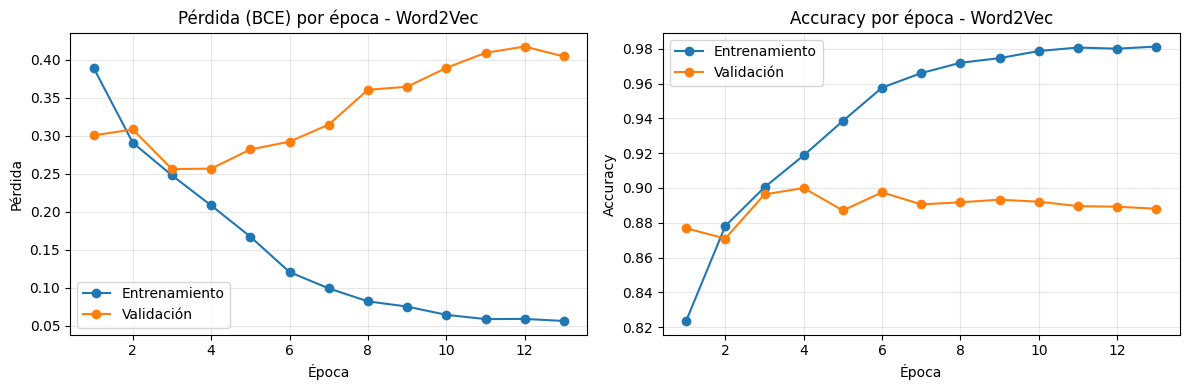

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epocas_x = range(1, len(historial_w2v["train_loss"]) + 1)

axes[0].plot(epocas_x, historial_w2v["train_loss"], marker="o", label="Entrenamiento")
axes[0].plot(epocas_x, historial_w2v["val_loss"], marker="o", label="Validación")
axes[0].set_title("Pérdida (BCE) por época - Word2Vec")
axes[0].set_xlabel("Época"); axes[0].set_ylabel("Pérdida")

axes[1].plot(epocas_x, historial_w2v["train_acc"], marker="o", label="Entrenamiento")
axes[1].plot(epocas_x, historial_w2v["val_acc"], marker="o", label="Validación")
axes[1].set_title("Accuracy por época - Word2Vec")
axes[1].set_xlabel("Época"); axes[1].set_ylabel("Accuracy")

for ax in axes:
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.show()

### 17. Evaluación en el conjunto de prueba (Word2Vec)

El mejor modelo Word2Vec se evalúa con el mismo conjunto de prueba (15 %) usado para GloVe.

Accuracy : 0.8971
Precisión: 0.9059
Recall   : 0.8868
F1-score : 0.8963
AUC      : 0.9607
Pérdida test: 0.2568 | mejor pérdida validación: 0.2561

              precision    recall  f1-score   support

    Negativa     0.8887    0.9075    0.8980      2973
    Positiva     0.9059    0.8868    0.8963      2986

    accuracy                         0.8971      5959
   macro avg     0.8973    0.8972    0.8971      5959
weighted avg     0.8973    0.8971    0.8971      5959



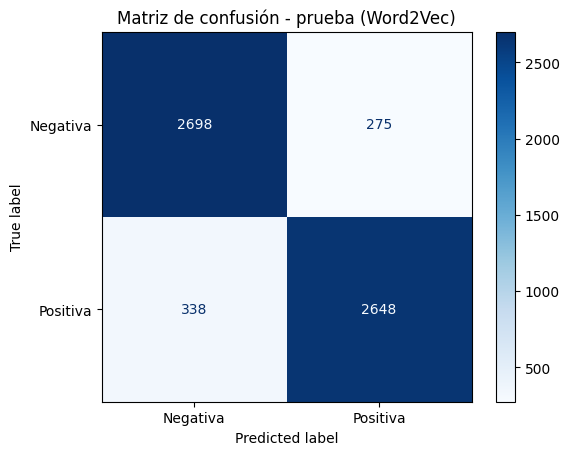

In [23]:
modelo_w2v.eval()
probs_w2v, reales_w2v = [], []
with torch.no_grad():
    for xb, yb in test_loader_w2v:
        probs_w2v.append(modelo_w2v(xb.to(device)).cpu())
        reales_w2v.append(yb)
probs_w2v = torch.cat(probs_w2v).numpy()
y_real_w2v = torch.cat(reales_w2v).numpy().astype(int)
y_pred_w2v = (probs_w2v >= 0.5).astype(int)

test_loss_w2v = criterio_w2v(torch.tensor(probs_w2v), torch.tensor(y_real_w2v, dtype=torch.float32)).item()
auc_w2v = roc_auc_score(y_real_w2v, probs_w2v)

print(f"Accuracy : {accuracy_score(y_real_w2v, y_pred_w2v):.4f}")
print(f"Precisión: {precision_score(y_real_w2v, y_pred_w2v):.4f}")
print(f"Recall   : {recall_score(y_real_w2v, y_pred_w2v):.4f}")
print(f"F1-score : {f1_score(y_real_w2v, y_pred_w2v):.4f}")
print(f"AUC      : {auc_w2v:.4f}")
print(f"Pérdida test: {test_loss_w2v:.4f} | mejor pérdida validación: {mejor_val_loss_w2v:.4f}\n")
print(classification_report(y_real_w2v, y_pred_w2v, target_names=["Negativa", "Positiva"], digits=4))

ConfusionMatrixDisplay(confusion_matrix(y_real_w2v, y_pred_w2v),
                       display_labels=["Negativa", "Positiva"]).plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión - prueba (Word2Vec)")
plt.show()

### 18. Comparación GloVe 300d vs. Word2Vec

Se comparan las métricas de prueba de los dos modelos y sus curvas ROC. Como los dos usan `BCELoss`, la pérdida en test también se puede comparar. Los modelos tienen la misma arquitectura (dos capas LSTM de 128 unidades con atención), secuencias de 300 tokens, la misma pérdida y el mismo early stopping. Por eso las diferencias vienen del embedding: GloVe de 300 dimensiones preentrenado contra Word2Vec de 100 dimensiones entrenado con las reseñas.

                                         Accuracy  Precisión  Recall  \
GloVe 300d (LSTM 2 capas + atención)       0.8861     0.9133  0.8537   
Word2Vec 100d (LSTM 2 capas + atención)    0.8971     0.9059  0.8868   

                                         F1-score     AUC  Pérdida test  \
GloVe 300d (LSTM 2 capas + atención)       0.8825  0.9554        0.2813   
Word2Vec 100d (LSTM 2 capas + atención)    0.8963  0.9607        0.2568   

                                         Épocas  
GloVe 300d (LSTM 2 capas + atención)       12.0  
Word2Vec 100d (LSTM 2 capas + atención)    13.0  


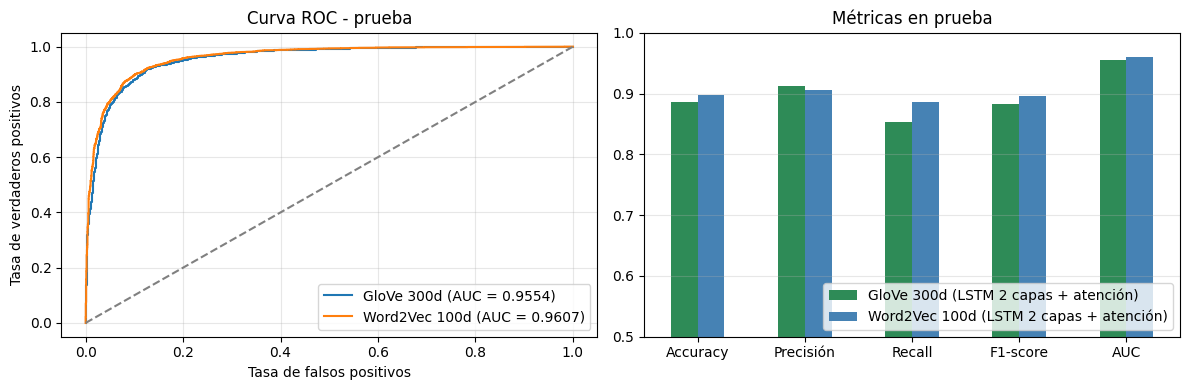

In [24]:
def metricas(y_true, y_hat, prob, perdida, historial_modelo):
    return {
        "Accuracy": accuracy_score(y_true, y_hat),
        "Precisión": precision_score(y_true, y_hat),
        "Recall": recall_score(y_true, y_hat),
        "F1-score": f1_score(y_true, y_hat),
        "AUC": roc_auc_score(y_true, prob),
        "Pérdida test": perdida,
        "Épocas": len(historial_modelo["train_loss"]),
    }

comparacion = pd.DataFrame({
    "GloVe 300d (LSTM 2 capas + atención)": metricas(y_real, y_pred, probs, test_loss, historial),
    "Word2Vec 100d (LSTM 2 capas + atención)": metricas(y_real_w2v, y_pred_w2v, probs_w2v, test_loss_w2v, historial_w2v),
}).T
print(comparacion.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for nombre, y_t, p in [("GloVe 300d", y_real, probs), ("Word2Vec 100d", y_real_w2v, probs_w2v)]:
    fpr, tpr, _ = roc_curve(y_t, p)
    axes[0].plot(fpr, tpr, label=f"{nombre} (AUC = {roc_auc_score(y_t, p):.4f})")
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set_title("Curva ROC - prueba")
axes[0].set_xlabel("Tasa de falsos positivos")
axes[0].set_ylabel("Tasa de verdaderos positivos")
axes[0].legend(); axes[0].grid(alpha=0.3)

cols = ["Accuracy", "Precisión", "Recall", "F1-score", "AUC"]
comparacion[cols].T.plot(kind="bar", ax=axes[1], rot=0, color=["seagreen", "steelblue"])
axes[1].set_ylim(0.5, 1.0)
axes[1].set_title("Métricas en prueba")
axes[1].grid(axis="y", alpha=0.3)
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()